In [ ]:
# ================================================================
# PHASE 4C — CELL 1
# SETUP
# ================================================================

from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import json

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from scipy.stats import (
    kruskal,
    fisher_exact
)


print("=" * 80)
print("PHASE 4C — IMAGE QUALITY & FAILURE SUBGROUP ANALYSIS")
print("=" * 80)

print("""
Research question:
How does CAMUS image-quality category relate to performance
through the frozen LV analysis pipeline?

Stages examined:
1. Segmentation
2. Quantitative measurements / EF
3. EF-band classification
4. Classifier confidence / uncertainty

Protocol:
• Frozen evaluation outputs only
• No model training
• No retraining
• No threshold tuning
• No pipeline modification
• ImageQuality is used as existing CAMUS metadata
• Subgroup analyses are descriptive/exploratory
• Small Poor-quality subgroup must be interpreted cautiously
""")

Mounted at /content/drive
PHASE 4C — IMAGE QUALITY & FAILURE SUBGROUP ANALYSIS

Research question:
How does CAMUS image-quality category relate to performance
through the frozen LV analysis pipeline?

Stages examined:
1. Segmentation
2. Quantitative measurements / EF
3. EF-band classification
4. Classifier confidence / uncertainty

Protocol:
• Frozen evaluation outputs only
• No model training
• No retraining
• No threshold tuning
• No pipeline modification
• ImageQuality is used as existing CAMUS metadata
• Subgroup analyses are descriptive/exploratory
• Small Poor-quality subgroup must be interpreted cautiously



In [ ]:
# ================================================================
# PHASE 4C — CELL 2
# PATHS
# ================================================================

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/CAMUS_FINAL"
)

PHASE4_ROOT = (
    PROJECT_ROOT
    / "phase4_robustness"
)

PHASE4A_DIR = (
    PHASE4_ROOT
    / "phase4A_error_propagation"
)

PHASE4B_DIR = (
    PHASE4_ROOT
    / "phase4B_confidence_uncertainty"
)

PHASE4C_DIR = (
    PHASE4_ROOT
    / "phase4C_image_quality_subgroups"
)

PHASE4C_TABLES_DIR = (
    PHASE4C_DIR
    / "tables"
)

PHASE4C_FIGURES_DIR = (
    PHASE4C_DIR
    / "figures"
)

PHASE4C_CONFIGS_DIR = (
    PHASE4C_DIR
    / "configs"
)


for directory in [
    PHASE4C_DIR,
    PHASE4C_TABLES_DIR,
    PHASE4C_FIGURES_DIR,
    PHASE4C_CONFIGS_DIR
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )


assert PHASE4A_DIR.exists()
assert PHASE4B_DIR.exists()


print("Phase 4A:")
print(PHASE4A_DIR)

print("\nPhase 4B:")
print(PHASE4B_DIR)

print("\nPhase 4C:")
print(PHASE4C_DIR)

print(
    "\n✓ Phase 4C directory structure ready."
)

Phase 4A:
/content/drive/MyDrive/CAMUS_FINAL/phase4_robustness/phase4A_error_propagation

Phase 4B:
/content/drive/MyDrive/CAMUS_FINAL/phase4_robustness/phase4B_confidence_uncertainty

Phase 4C:
/content/drive/MyDrive/CAMUS_FINAL/phase4_robustness/phase4C_image_quality_subgroups

✓ Phase 4C directory structure ready.


In [ ]:
# ================================================================
# PHASE 4C — CELL 3
# VERIFY PREVIOUS PHASES
# ================================================================

PHASE4A_COMPLETE_PATH = (
    PHASE4A_DIR
    / "PHASE4A_COMPLETE.json"
)

PHASE4B_COMPLETE_PATH = (
    PHASE4B_DIR
    / "PHASE4B_COMPLETE.json"
)


assert PHASE4A_COMPLETE_PATH.exists()
assert PHASE4B_COMPLETE_PATH.exists()


with open(
    PHASE4A_COMPLETE_PATH,
    "r"
) as file:
    phase4A_status = json.load(file)


with open(
    PHASE4B_COMPLETE_PATH,
    "r"
) as file:
    phase4B_status = json.load(file)


assert (
    phase4A_status["status"]
    == "COMPLETE_AND_FROZEN"
)

assert (
    phase4B_status["status"]
    == "COMPLETE_AND_FROZEN"
)


print("=" * 80)
print("PREVIOUS PHASE STATUS")
print("=" * 80)

print(
    "\nPhase 4A:",
    phase4A_status["status"]
)

print(
    "Phase 4B:",
    phase4B_status["status"]
)

print(
    "\n✓ Previous analyses confirmed frozen."
)

PREVIOUS PHASE STATUS

Phase 4A: COMPLETE_AND_FROZEN
Phase 4B: COMPLETE_AND_FROZEN

✓ Previous analyses confirmed frozen.


In [ ]:
# ================================================================
# PHASE 4C — CELL 4
# LOAD FROZEN ANALYSIS TABLES
# ================================================================

PHASE4A_CANONICAL_PATH = (
    PHASE4A_DIR
    / "tables"
    / "phase4A_canonical_patient_error_chain.csv"
)

PHASE4B_PATIENT_PATH = (
    PHASE4B_DIR
    / "tables"
    / "phase4B_patient_confidence_analysis.csv"
)


assert PHASE4A_CANONICAL_PATH.exists()
assert PHASE4B_PATIENT_PATH.exists()


phase4A_df = pd.read_csv(
    PHASE4A_CANONICAL_PATH
)

phase4B_df = pd.read_csv(
    PHASE4B_PATIENT_PATH
)


assert len(phase4A_df) == 50
assert len(phase4B_df) == 50

assert phase4A_df[
    "patient_id"
].nunique() == 50

assert phase4B_df[
    "patient_id"
].nunique() == 50


print("=" * 80)
print("FROZEN INPUTS LOADED")
print("=" * 80)

print(
    "\nPhase 4A shape:",
    phase4A_df.shape
)

print(
    "Phase 4B shape:",
    phase4B_df.shape
)

FROZEN INPUTS LOADED

Phase 4A shape: (50, 61)
Phase 4B shape: (50, 23)


In [ ]:
# ================================================================
# PHASE 4C — CELL 5
# BUILD CANONICAL IMAGE-QUALITY ANALYSIS TABLE
# ================================================================

confidence_keep = phase4B_df[[
    "patient_id",
    "model_confidence",
    "confidence_margin",
    "normalized_entropy"
]].copy()


phase4C_df = phase4A_df.merge(
    confidence_keep,
    on="patient_id",
    how="inner",
    validate="one_to_one",
    suffixes=("", "_phase4B")
)


phase4C_df = (
    phase4C_df
    .sort_values(
        "patient_id"
    )
    .reset_index(
        drop=True
    )
)


assert len(phase4C_df) == 50
assert phase4C_df["patient_id"].nunique() == 50


# ---------------------------------------------------------------
# REQUIRED COLUMNS
# ---------------------------------------------------------------

required_columns = [

    "patient_id",
    "image_quality",

    "ED_dice",
    "ES_dice",

    "ED_area_abs_relative_error_pct",
    "ES_area_abs_relative_error_pct",

    "EDV_abs_error_ml",
    "ESV_abs_error_ml",

    "segmentation_induced_EF_abs_error_pp",
    "end_to_end_EF_abs_error_pp",

    "classification_error",

    "model_confidence",
    "confidence_margin",
    "normalized_entropy"
]


missing = [
    column
    for column in required_columns
    if column not in phase4C_df.columns
]


assert not missing, (
    f"Missing required columns: {missing}"
)


print("=" * 80)
print("PHASE 4C CANONICAL TABLE")
print("=" * 80)

print(
    "\nShape:",
    phase4C_df.shape
)

print(
    "\nImage-quality distribution:"
)

print(
    phase4C_df[
        "image_quality"
    ].value_counts()
)


print(
    "\n✓ Canonical Phase 4C table ready."
)

PHASE 4C CANONICAL TABLE

Shape: (50, 64)

Image-quality distribution:
image_quality
Good      30
Medium    13
Poor       7
Name: count, dtype: int64

✓ Canonical Phase 4C table ready.


In [ ]:
# ================================================================
# PHASE 4C — CELL 6
# PERFORMANCE SUMMARY BY IMAGE QUALITY
# ================================================================

QUALITY_ORDER = [
    "Good",
    "Medium",
    "Poor"
]


quality_summary_records = []


for quality in QUALITY_ORDER:

    subset = phase4C_df[
        phase4C_df[
            "image_quality"
        ] == quality
    ]


    record = {

        "image_quality":
            quality,

        "n":
            len(subset),

        # ---------------- SEGMENTATION ----------------

        "median_ED_dice":
            subset[
                "ED_dice"
            ].median(),

        "median_ES_dice":
            subset[
                "ES_dice"
            ].median(),

        "median_ED_area_error_pct":
            subset[
                "ED_area_abs_relative_error_pct"
            ].median(),

        "median_ES_area_error_pct":
            subset[
                "ES_area_abs_relative_error_pct"
            ].median(),

        # ---------------- VOLUME ----------------

        "median_EDV_error_ml":
            subset[
                "EDV_abs_error_ml"
            ].median(),

        "median_ESV_error_ml":
            subset[
                "ESV_abs_error_ml"
            ].median(),

        # ---------------- EF ----------------

        "median_segmentation_EF_error_pp":
            subset[
                "segmentation_induced_EF_abs_error_pp"
            ].median(),

        "median_end_to_end_EF_error_pp":
            subset[
                "end_to_end_EF_abs_error_pp"
            ].median(),

        # ---------------- CLASSIFICATION ----------------

        "classification_correct":
            int(
                (
                    subset[
                        "classification_error"
                    ] == 0
                ).sum()
            ),

        "classification_incorrect":
            int(
                subset[
                    "classification_error"
                ].sum()
            ),

        "classification_accuracy_pct":
            (
                (
                    subset[
                        "classification_error"
                    ] == 0
                ).mean()
                * 100
            ),

        # ---------------- CONFIDENCE ----------------

        "median_model_confidence":
            subset[
                "model_confidence"
            ].median(),

        "median_confidence_margin":
            subset[
                "confidence_margin"
            ].median(),

        "median_normalized_entropy":
            subset[
                "normalized_entropy"
            ].median()
    }


    quality_summary_records.append(
        record
    )


phase4C_quality_summary_df = pd.DataFrame(
    quality_summary_records
)


print("=" * 100)
print("FROZEN PIPELINE PERFORMANCE BY CAMUS IMAGE QUALITY")
print("=" * 100)


display(
    phase4C_quality_summary_df.round(4)
)


print(
    "\nIMPORTANT:"
)

print(
    "Poor-quality subgroup contains only",
    int(
        (
            phase4C_df[
                "image_quality"
            ] == "Poor"
        ).sum()
    ),
    "patients."
)

print(
    "Subgroup differences are descriptive and should "
    "not be interpreted as population-level estimates."
)

FROZEN PIPELINE PERFORMANCE BY CAMUS IMAGE QUALITY


,image_quality,n,median_ED_dice,median_ES_dice,median_ED_area_error_pct,median_ES_area_error_pct,median_EDV_error_ml,median_ESV_error_ml,median_segmentation_EF_error_pp,median_end_to_end_EF_error_pp,classification_correct,classification_incorrect,classification_accuracy_pct,median_model_confidence,median_confidence_margin,median_normalized_entropy
0,Good,30,0.9519,0.9355,4.0344,4.7151,7.0949,3.7216,3.6443,5.2637,24,6,80.0000,0.6974,0.4112,0.6229
1,Medium,13,0.9439,0.9011,7.4585,14.0359,14.2677,9.3147,4.6977,8.2648,7,6,53.8462,0.6918,0.3971,0.6406
2,Poor,7,0.9130,0.9295,9.0614,8.1780,16.5111,8.9793,9.0898,7.6206,4,3,57.1429,0.7082,0.4280,0.5939



IMPORTANT:
Poor-quality subgroup contains only 7 patients.
Subgroup differences are descriptive and should not be interpreted as population-level estimates.


In [ ]:
# ================================================================
# PHASE 4C — CELL 7
# EXPLORATORY KRUSKAL-WALLIS SUBGROUP TESTS
# ================================================================

quality_test_variables = {

    "ED Dice":
        "ED_dice",

    "ES Dice":
        "ES_dice",

    "ED area error (%)":
        "ED_area_abs_relative_error_pct",

    "ES area error (%)":
        "ES_area_abs_relative_error_pct",

    "EDV error (mL)":
        "EDV_abs_error_ml",

    "ESV error (mL)":
        "ESV_abs_error_ml",

    "Segmentation-induced EF error (pp)":
        "segmentation_induced_EF_abs_error_pp",

    "End-to-end EF error (pp)":
        "end_to_end_EF_abs_error_pp",

    "Model confidence":
        "model_confidence",

    "Confidence margin":
        "confidence_margin",

    "Normalized entropy":
        "normalized_entropy"
}


quality_test_results = []


for display_name, column in quality_test_variables.items():

    groups = [

        phase4C_df.loc[
            phase4C_df[
                "image_quality"
            ] == quality,
            column
        ].dropna().to_numpy()

        for quality in QUALITY_ORDER
    ]


    statistic, p_value = kruskal(
        *groups
    )


    quality_test_results.append({

        "metric":
            display_name,

        "kruskal_H":
            statistic,

        "p_value":
            p_value
    })


phase4C_quality_tests_df = pd.DataFrame(
    quality_test_results
)


print("=" * 80)
print("IMAGE-QUALITY SUBGROUP TESTS")
print("=" * 80)


display(
    phase4C_quality_tests_df.round({
        "kruskal_H": 4,
        "p_value": 6
    })
)


print(
    "\nNOTE:"
)

print(
    "• These are exploratory omnibus comparisons."
)

print(
    "• Multiple outcomes are being examined."
)

print(
    "• No post-hoc pairwise testing should be performed "
    "automatically from isolated p-values."
)

print(
    "• Poor-quality n is very small."
)

IMAGE-QUALITY SUBGROUP TESTS


,metric,kruskal_H,p_value
0,ED Dice,5.9425,0.051240
1,ES Dice,4.4024,0.110671
2,ED area error (%),5.2050,0.074090
3,ES area error (%),5.8610,0.053370
4,EDV error (mL),3.4171,0.181128
5,ESV error (mL),7.9553,0.018730
6,Segmentation-induced EF error (pp),4.6883,0.095928
7,End-to-end EF error (pp),4.0224,0.133830
8,Model confidence,0.9200,0.631273
9,Confidence margin,0.3671,0.832303



NOTE:
• These are exploratory omnibus comparisons.
• Multiple outcomes are being examined.
• No post-hoc pairwise testing should be performed automatically from isolated p-values.
• Poor-quality n is very small.


In [ ]:
# ================================================================
# PHASE 4C — CELL 8
# CLASSIFICATION FAILURE BY IMAGE QUALITY
# ================================================================

classification_quality_table = pd.crosstab(

    phase4C_df[
        "image_quality"
    ],

    phase4C_df[
        "classification_error"
    ]
)


classification_quality_table = (
    classification_quality_table
    .reindex(
        QUALITY_ORDER,
        fill_value=0
    )
)


for column in [
    0,
    1
]:

    if column not in classification_quality_table.columns:

        classification_quality_table[
            column
        ] = 0


classification_quality_table = (
    classification_quality_table[
        [0, 1]
    ]
)


classification_quality_table.columns = [
    "correct",
    "misclassified"
]


classification_quality_table[
    "total"
] = (
    classification_quality_table[
        "correct"
    ]
    +
    classification_quality_table[
        "misclassified"
    ]
)


classification_quality_table[
    "misclassification_rate_pct"
] = (
    classification_quality_table[
        "misclassified"
    ]
    /
    classification_quality_table[
        "total"
    ]
    * 100
)


classification_quality_table = (
    classification_quality_table
    .reset_index()
)


print("=" * 80)
print("CLASSIFICATION FAILURE BY IMAGE QUALITY")
print("=" * 80)


display(
    classification_quality_table.round(2)
)


print(
    "\nInterpretation rule:"
)

print(
    "Compare descriptive rates, but avoid strong claims "
    "because Medium and especially Poor subgroup sizes are small."
)

CLASSIFICATION FAILURE BY IMAGE QUALITY


,image_quality,correct,misclassified,total,misclassification_rate_pct
0,Good,24,6,30,20.00
1,Medium,7,6,13,46.15
2,Poor,4,3,7,42.86



Interpretation rule:
Compare descriptive rates, but avoid strong claims because Medium and especially Poor subgroup sizes are small.


In [ ]:
# ================================================================
# PHASE 4C — CELL 9
# DESCRIPTIVE EFFECT MAGNITUDES RELATIVE TO GOOD QUALITY
# ================================================================

effect_variables = {

    "ED Dice":
        "ED_dice",

    "ES Dice":
        "ES_dice",

    "ED area error (%)":
        "ED_area_abs_relative_error_pct",

    "ES area error (%)":
        "ES_area_abs_relative_error_pct",

    "EDV error (mL)":
        "EDV_abs_error_ml",

    "ESV error (mL)":
        "ESV_abs_error_ml",

    "Segmentation-induced EF error (pp)":
        "segmentation_induced_EF_abs_error_pp",

    "End-to-end EF error (pp)":
        "end_to_end_EF_abs_error_pp",

    "Model confidence":
        "model_confidence",

    "Confidence margin":
        "confidence_margin",

    "Normalized entropy":
        "normalized_entropy"
}


quality_effect_records = []


for display_name, column in effect_variables.items():

    medians = (
        phase4C_df
        .groupby("image_quality")[column]
        .median()
    )

    good_median = medians["Good"]

    for comparison_quality in [
        "Medium",
        "Poor"
    ]:

        comparison_median = medians[
            comparison_quality
        ]

        quality_effect_records.append({

            "metric":
                display_name,

            "comparison":
                f"{comparison_quality} - Good",

            "good_median":
                good_median,

            "comparison_median":
                comparison_median,

            "median_difference":
                comparison_median - good_median
        })


phase4C_effect_df = pd.DataFrame(
    quality_effect_records
)


print("=" * 90)
print("DESCRIPTIVE MEDIAN DIFFERENCES RELATIVE TO GOOD QUALITY")
print("=" * 90)

display(
    phase4C_effect_df.round(4)
)


print("\nInterpretation:")
print(
    "For Dice and confidence, negative differences indicate lower values."
)

print(
    "For error and entropy measures, positive differences indicate larger values."
)

print(
    "\nThese are descriptive effect magnitudes, not adjusted or causal effects."
)

DESCRIPTIVE MEDIAN DIFFERENCES RELATIVE TO GOOD QUALITY


,metric,comparison,good_median,comparison_median,median_difference
0,ED Dice,Medium - Good,0.9519,0.9439,-0.0079
1,ED Dice,Poor - Good,0.9519,0.9130,-0.0389
2,ES Dice,Medium - Good,0.9355,0.9011,-0.0344
3,ES Dice,Poor - Good,0.9355,0.9295,-0.0059
4,ED area error (%),Medium - Good,4.0344,7.4585,3.4241
5,ED area error (%),Poor - Good,4.0344,9.0614,5.0270
6,ES area error (%),Medium - Good,4.7151,14.0359,9.3208
7,ES area error (%),Poor - Good,4.7151,8.1780,3.4629
8,EDV error (mL),Medium - Good,7.0949,14.2677,7.1729
9,EDV error (mL),Poor - Good,7.0949,16.5111,9.4162



Interpretation:
For Dice and confidence, negative differences indicate lower values.
For error and entropy measures, positive differences indicate larger values.

These are descriptive effect magnitudes, not adjusted or causal effects.


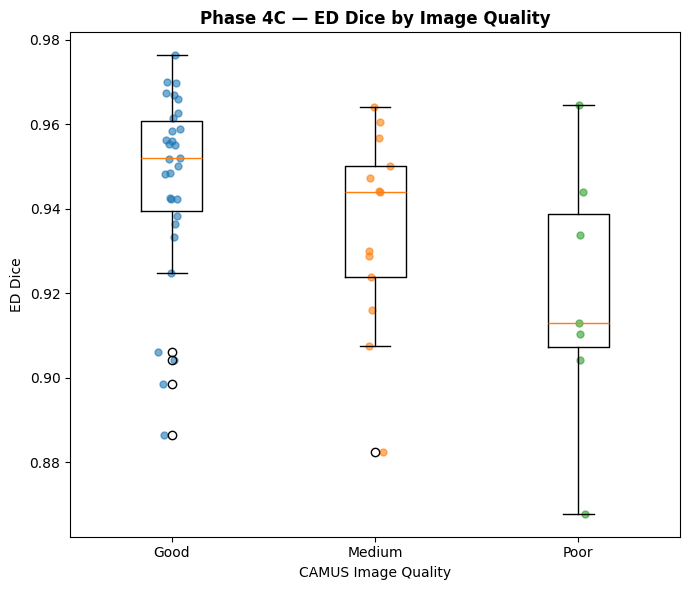

Saved: /content/drive/MyDrive/CAMUS_FINAL/phase4_robustness/phase4C_image_quality_subgroups/figures/phase4C_quality_ED_dice.png


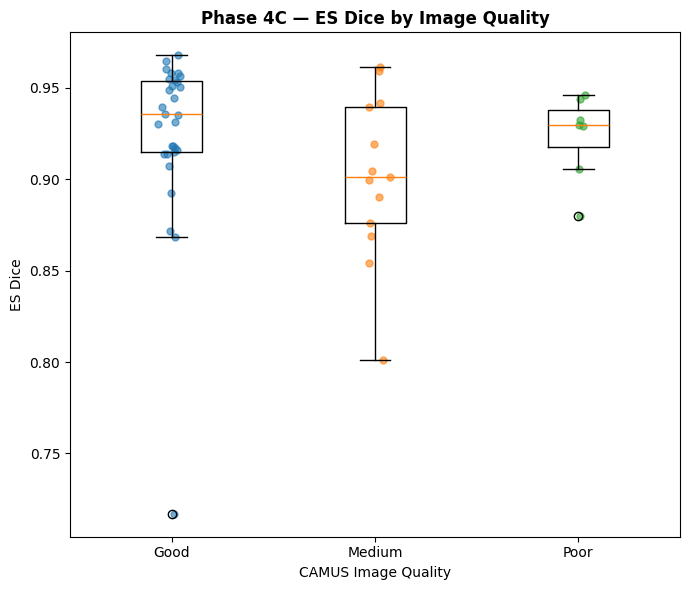

Saved: /content/drive/MyDrive/CAMUS_FINAL/phase4_robustness/phase4C_image_quality_subgroups/figures/phase4C_quality_ES_dice.png


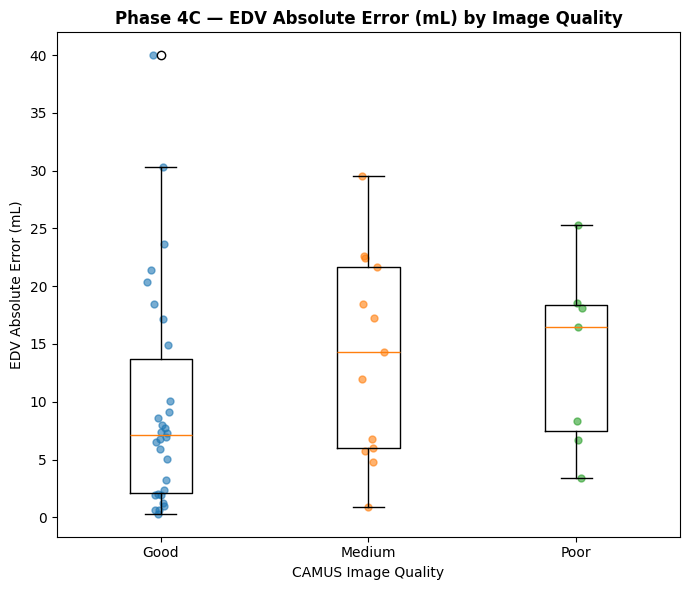

Saved: /content/drive/MyDrive/CAMUS_FINAL/phase4_robustness/phase4C_image_quality_subgroups/figures/phase4C_quality_EDV_error.png


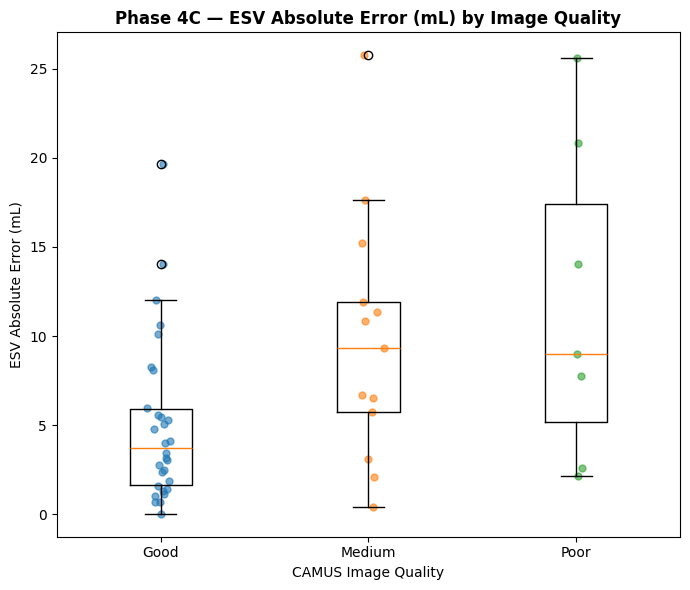

Saved: /content/drive/MyDrive/CAMUS_FINAL/phase4_robustness/phase4C_image_quality_subgroups/figures/phase4C_quality_ESV_error.png


In [ ]:
# ================================================================
# PHASE 4C — CELL 10
# IMAGE QUALITY — SEGMENTATION / QUANTIFICATION FIGURES
# ================================================================

figure_variables = [

    (
        "ED_dice",
        "ED Dice",
        "phase4C_quality_ED_dice.png"
    ),

    (
        "ES_dice",
        "ES Dice",
        "phase4C_quality_ES_dice.png"
    ),

    (
        "EDV_abs_error_ml",
        "EDV Absolute Error (mL)",
        "phase4C_quality_EDV_error.png"
    ),

    (
        "ESV_abs_error_ml",
        "ESV Absolute Error (mL)",
        "phase4C_quality_ESV_error.png"
    )
]


for column, ylabel, filename in figure_variables:

    data = [

        phase4C_df.loc[
            phase4C_df["image_quality"] == quality,
            column
        ].to_numpy()

        for quality in QUALITY_ORDER
    ]


    fig, ax = plt.subplots(
        figsize=(7, 6)
    )


    ax.boxplot(
        data,
        tick_labels=QUALITY_ORDER,
        showfliers=True
    )


    # Individual patients
    rng = np.random.default_rng(42)

    for position, values in enumerate(
        data,
        start=1
    ):

        jitter = rng.normal(
            position,
            0.035,
            size=len(values)
        )

        ax.scatter(
            jitter,
            values,
            alpha=0.60,
            s=25
        )


    ax.set_xlabel(
        "CAMUS Image Quality"
    )

    ax.set_ylabel(
        ylabel
    )

    ax.set_title(
        f"Phase 4C — {ylabel} by Image Quality",
        fontweight="bold"
    )


    plt.tight_layout()


    output_path = (
        PHASE4C_FIGURES_DIR
        / filename
    )


    plt.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


    print(
        "Saved:",
        output_path
    )

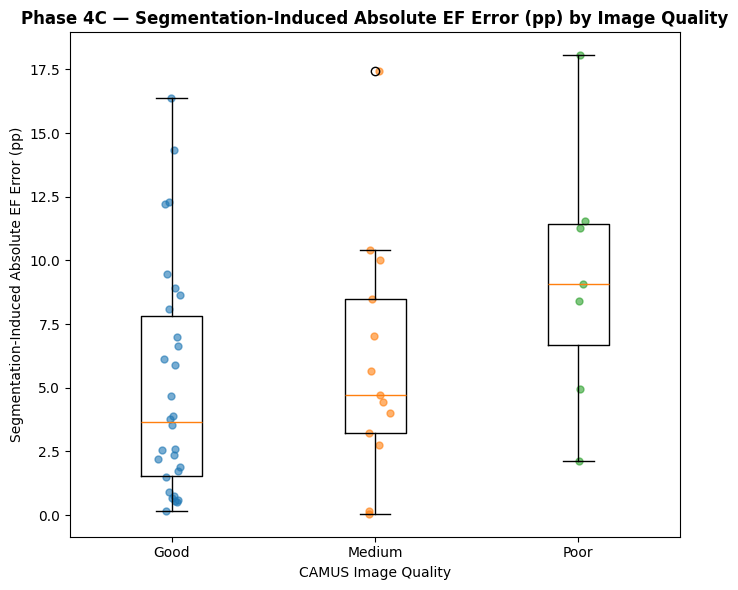

Saved: /content/drive/MyDrive/CAMUS_FINAL/phase4_robustness/phase4C_image_quality_subgroups/figures/phase4C_quality_segmentation_EF_error.png


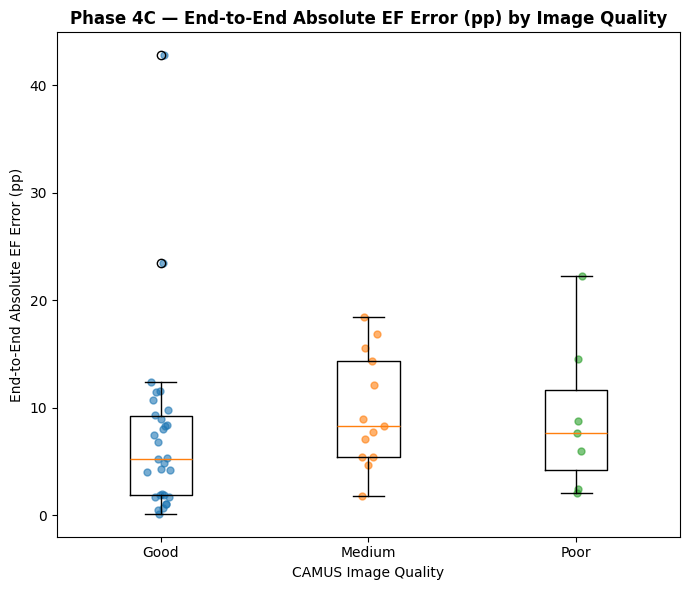

Saved: /content/drive/MyDrive/CAMUS_FINAL/phase4_robustness/phase4C_image_quality_subgroups/figures/phase4C_quality_end_to_end_EF_error.png


In [ ]:
# ================================================================
# PHASE 4C — CELL 11
# IMAGE QUALITY — DOWNSTREAM EF ERROR FIGURES
# ================================================================

ef_figure_variables = [

    (
        "segmentation_induced_EF_abs_error_pp",
        "Segmentation-Induced Absolute EF Error (pp)",
        "phase4C_quality_segmentation_EF_error.png"
    ),

    (
        "end_to_end_EF_abs_error_pp",
        "End-to-End Absolute EF Error (pp)",
        "phase4C_quality_end_to_end_EF_error.png"
    )
]


for column, ylabel, filename in ef_figure_variables:

    data = [

        phase4C_df.loc[
            phase4C_df["image_quality"] == quality,
            column
        ].to_numpy()

        for quality in QUALITY_ORDER
    ]


    fig, ax = plt.subplots(
        figsize=(7, 6)
    )


    ax.boxplot(
        data,
        tick_labels=QUALITY_ORDER,
        showfliers=True
    )


    rng = np.random.default_rng(42)

    for position, values in enumerate(
        data,
        start=1
    ):

        jitter = rng.normal(
            position,
            0.035,
            size=len(values)
        )

        ax.scatter(
            jitter,
            values,
            alpha=0.60,
            s=25
        )


    ax.set_xlabel(
        "CAMUS Image Quality"
    )

    ax.set_ylabel(
        ylabel
    )

    ax.set_title(
        f"Phase 4C — {ylabel} by Image Quality",
        fontweight="bold"
    )


    plt.tight_layout()


    output_path = (
        PHASE4C_FIGURES_DIR
        / filename
    )


    plt.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


    print(
        "Saved:",
        output_path
    )

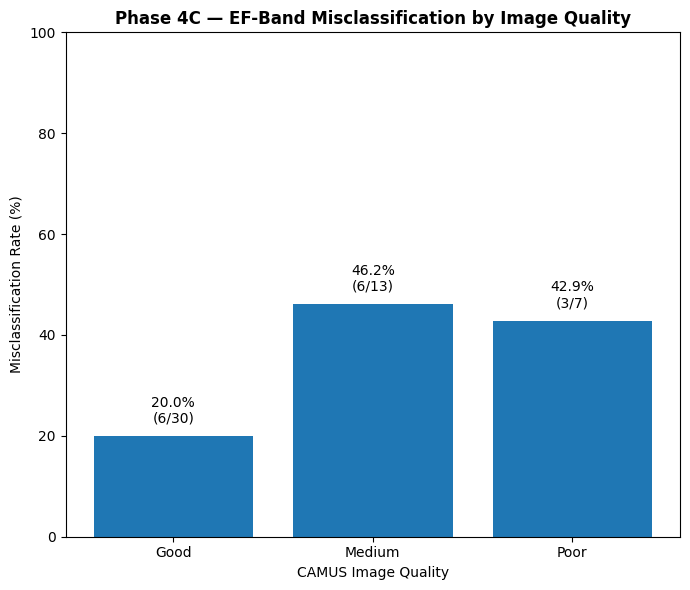

Saved: /content/drive/MyDrive/CAMUS_FINAL/phase4_robustness/phase4C_image_quality_subgroups/figures/phase4C_classification_failure_by_quality.png


In [ ]:
# ================================================================
# PHASE 4C — CELL 12
# CLASSIFICATION FAILURE BY IMAGE QUALITY FIGURE
# ================================================================

plot_df = (
    classification_quality_table
    .copy()
    .set_index("image_quality")
    .reindex(QUALITY_ORDER)
    .reset_index()
)


fig, ax = plt.subplots(
    figsize=(7, 6)
)


bars = ax.bar(
    plot_df["image_quality"],
    plot_df["misclassification_rate_pct"]
)


ax.set_xlabel(
    "CAMUS Image Quality"
)

ax.set_ylabel(
    "Misclassification Rate (%)"
)

ax.set_ylim(
    0,
    100
)

ax.set_title(
    "Phase 4C — EF-Band Misclassification by Image Quality",
    fontweight="bold"
)


for bar, (_, row) in zip(
    bars,
    plot_df.iterrows()
):

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2,
        (
            f"{row['misclassification_rate_pct']:.1f}%\n"
            f"({int(row['misclassified'])}/{int(row['total'])})"
        ),
        ha="center",
        va="bottom",
        fontsize=10
    )


plt.tight_layout()


CLASSIFICATION_QUALITY_FIGURE_PATH = (
    PHASE4C_FIGURES_DIR
    / "phase4C_classification_failure_by_quality.png"
)


plt.savefig(
    CLASSIFICATION_QUALITY_FIGURE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


print(
    "Saved:",
    CLASSIFICATION_QUALITY_FIGURE_PATH
)

In [ ]:
# ================================================================
# PHASE 4C — CELL 13
# SAVE ANALYSIS TABLES
# ================================================================

PHASE4C_CANONICAL_PATH = (
    PHASE4C_TABLES_DIR
    / "phase4C_canonical_image_quality_analysis.csv"
)

PHASE4C_SUMMARY_TABLE_PATH = (
    PHASE4C_TABLES_DIR
    / "phase4C_performance_by_image_quality.csv"
)

PHASE4C_TESTS_PATH = (
    PHASE4C_TABLES_DIR
    / "phase4C_image_quality_kruskal_tests.csv"
)

PHASE4C_CLASSIFICATION_PATH = (
    PHASE4C_TABLES_DIR
    / "phase4C_classification_by_image_quality.csv"
)

PHASE4C_EFFECT_PATH = (
    PHASE4C_TABLES_DIR
    / "phase4C_descriptive_quality_effects.csv"
)


phase4C_df.to_csv(
    PHASE4C_CANONICAL_PATH,
    index=False
)

phase4C_quality_summary_df.to_csv(
    PHASE4C_SUMMARY_TABLE_PATH,
    index=False
)

phase4C_quality_tests_df.to_csv(
    PHASE4C_TESTS_PATH,
    index=False
)

classification_quality_table.to_csv(
    PHASE4C_CLASSIFICATION_PATH,
    index=False
)

phase4C_effect_df.to_csv(
    PHASE4C_EFFECT_PATH,
    index=False
)


print("=" * 80)
print("PHASE 4C TABLES SAVED")
print("=" * 80)


for path in [

    PHASE4C_CANONICAL_PATH,
    PHASE4C_SUMMARY_TABLE_PATH,
    PHASE4C_TESTS_PATH,
    PHASE4C_CLASSIFICATION_PATH,
    PHASE4C_EFFECT_PATH

]:

    print(
        "✓",
        path
    )

PHASE 4C TABLES SAVED
✓ /content/drive/MyDrive/CAMUS_FINAL/phase4_robustness/phase4C_image_quality_subgroups/tables/phase4C_canonical_image_quality_analysis.csv
✓ /content/drive/MyDrive/CAMUS_FINAL/phase4_robustness/phase4C_image_quality_subgroups/tables/phase4C_performance_by_image_quality.csv
✓ /content/drive/MyDrive/CAMUS_FINAL/phase4_robustness/phase4C_image_quality_subgroups/tables/phase4C_image_quality_kruskal_tests.csv
✓ /content/drive/MyDrive/CAMUS_FINAL/phase4_robustness/phase4C_image_quality_subgroups/tables/phase4C_classification_by_image_quality.csv
✓ /content/drive/MyDrive/CAMUS_FINAL/phase4_robustness/phase4C_image_quality_subgroups/tables/phase4C_descriptive_quality_effects.csv


In [ ]:
# ================================================================
# PHASE 4C — CELL 14
# FINAL RECORD + COMPLETION MARKER
# ================================================================

phase4C_final_record = {

    "phase":
        "Phase 4C",

    "title":
        "Image Quality and Failure Subgroup Analysis",

    "status":
        "COMPLETE_AND_FROZEN",

    "n_patients":
        50,

    "image_quality_counts": {
        "Good": 30,
        "Medium": 13,
        "Poor": 7
    },

    "main_findings": [

        (
            "Good-quality cases generally showed the strongest "
            "performance across the frozen pipeline, including "
            "higher segmentation overlap, lower quantitative "
            "errors, and higher EF-band classification accuracy."
        ),

        (
            "Median ED Dice decreased from 0.9519 in Good-quality "
            "cases to 0.9439 in Medium and 0.9130 in Poor cases."
        ),

        (
            "Image-quality effects were not uniform across ED and "
            "ES. Medium-quality cases showed the largest median "
            "ES area error and ESV error, whereas Poor-quality "
            "cases showed the lowest median ED Dice."
        ),

        (
            "Median segmentation-induced EF error was 3.6443 pp "
            "for Good, 4.6977 pp for Medium, and 9.0898 pp for "
            "Poor-quality cases."
        ),

        (
            "Median end-to-end EF error was 5.2637 pp for Good, "
            "8.2648 pp for Medium, and 7.6206 pp for Poor-quality "
            "cases. Therefore, downstream degradation was not "
            "strictly monotonic with the ordinal quality labels."
        ),

        (
            "EF-band classification accuracy was 80.0% in Good, "
            "53.85% in Medium, and 57.14% in Poor-quality cases."
        ),

        (
            "Classifier confidence, confidence margin, and entropy "
            "were similar across image-quality groups, indicating "
            "that classifier confidence did not clearly reflect "
            "CAMUS image-quality category."
        ),

        (
            "Among the exploratory Kruskal-Wallis comparisons, "
            "ESV absolute error showed the clearest subgroup "
            "difference (H = 7.9553, p = 0.0187). However, multiple "
            "outcomes were examined and the Poor-quality subgroup "
            "contained only seven patients, so this result is not "
            "treated as confirmatory evidence."
        )
    ],

    "interpretation": (

        "CAMUS image quality is associated descriptively with "
        "performance degradation in parts of the frozen pipeline, "
        "but its effect is stage-specific rather than uniformly "
        "monotonic. Good-quality images generally perform better, "
        "while Medium and Poor cases show different error patterns "
        "across ED/ES segmentation, quantitative measurements, and "
        "classification. Image quality therefore provides useful "
        "context for robustness analysis but cannot by itself serve "
        "as a complete patient-level reliability indicator."
    ),

    "application_implication": (

        "Image-quality information may be useful as one component "
        "of a future quality-control or review mechanism. The "
        "present results do not justify rejecting or accepting an "
        "analysis solely from the CAMUS Good/Medium/Poor category."
    ),

    "limitations": [

        "Only 50 evaluation patients were analyzed.",

        "The Poor-quality subgroup contained only seven patients.",

        "Subgroup analyses were exploratory and multiple outcomes "
        "were examined.",

        "No pairwise post-hoc significance testing was used to "
        "select findings.",

        "CAMUS ImageQuality is existing dataset metadata and is "
        "not an independently validated automatic quality score "
        "from the current system.",

        "Associations do not establish causality.",

        "The evaluation set had historical pilot exposure."
    ],

    "pipeline_changes_after_analysis":
        False
}


PHASE4C_FINAL_RECORD_PATH = (
    PHASE4C_CONFIGS_DIR
    / "phase4C_final_record.json"
)


with open(
    PHASE4C_FINAL_RECORD_PATH,
    "w"
) as file:

    json.dump(
        phase4C_final_record,
        file,
        indent=4
    )


# ---------------------------------------------------------------
# CHECK REQUIRED OUTPUTS
# ---------------------------------------------------------------

required_outputs = [

    PHASE4C_CANONICAL_PATH,
    PHASE4C_SUMMARY_TABLE_PATH,
    PHASE4C_TESTS_PATH,
    PHASE4C_CLASSIFICATION_PATH,
    PHASE4C_EFFECT_PATH,
    PHASE4C_FINAL_RECORD_PATH
]


for path in required_outputs:

    assert path.exists(), (
        f"Missing required output: {path}"
    )


# ---------------------------------------------------------------
# COMPLETION MARKER
# ---------------------------------------------------------------

completion_record = {

    "phase":
        "Phase 4C",

    "title":
        "Image Quality and Failure Subgroup Analysis",

    "status":
        "COMPLETE_AND_FROZEN",

    "n_patients":
        50,

    "model_training":
        False,

    "threshold_tuning":
        False,

    "post_hoc_pipeline_modification":
        False,

    "next_phase":
        "Phase 4D — Representative Failure Case Analysis"
}


PHASE4C_COMPLETION_PATH = (
    PHASE4C_DIR
    / "PHASE4C_COMPLETE.json"
)


with open(
    PHASE4C_COMPLETION_PATH,
    "w"
) as file:

    json.dump(
        completion_record,
        file,
        indent=4
    )


print("=" * 80)
print("PHASE 4C COMPLETE AND FROZEN")
print("=" * 80)

print(
    "\nFinal record:",
    PHASE4C_FINAL_RECORD_PATH
)

print(
    "\nCompletion marker:",
    PHASE4C_COMPLETION_PATH
)

print(
    "\n✓ No model changes."
)

print(
    "✓ No thresholds selected."
)

print(
    "✓ No pairwise p-value fishing."
)

print(
    "\nNext: Phase 4D — Representative Failure Case Analysis"
)

PHASE 4C COMPLETE AND FROZEN

Final record: /content/drive/MyDrive/CAMUS_FINAL/phase4_robustness/phase4C_image_quality_subgroups/configs/phase4C_final_record.json

Completion marker: /content/drive/MyDrive/CAMUS_FINAL/phase4_robustness/phase4C_image_quality_subgroups/PHASE4C_COMPLETE.json

✓ No model changes.
✓ No thresholds selected.
✓ No pairwise p-value fishing.

Next: Phase 4D — Representative Failure Case Analysis
